# **Credit Risk Assessment**<br>



# 1. Load the Data<br>
We will bring in the loan applicant data.<br>
* This data has details like income, age, and loan amount.<br>
* It also tells us who repaid and who defaulted.<br>

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
df = pd.read_csv("/content/credit_risk_dataset.csv")
df.head()


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


-- Here the target column we have is '***loan_status***'<br>
-- We need to check whether the person is eligible for loan or not

2. Exploratory Data Analysis (EDA)<br>

* Here we simply look at the data before touching it.
* We want to understand it first, then work on it.
**Basic info about the data**
* Check how many rows and columns we have.
* Check the data type of each column.

In [55]:
# shape of the dataset
df.shape

(32581, 12)

In [56]:
# data type of the columns dataset
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


None

-- Here we acn see some of the columns are object type<br>
-- and we need to apply label-encoding or onehot-encoding

**Missing values**
* Find out which columns have empty or missing values.
* This tells us where we may need to fix things later.


In [57]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


**Target balance**
* Check how many people defaulted vs how many repaid.
* This tells us if our data is balanced or imbalanced.

In [58]:
df['loan_status'].unique()

array([1, 0])

-- We have two classes <br>
[ "1": The person is getting the loan,<br>
  "0" : The person is not getting the loan ]

In [59]:
# Check class imbalance
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


-- Here is a class imbalance of "0" class<br>
Let's plot this as a graph to get better understanding

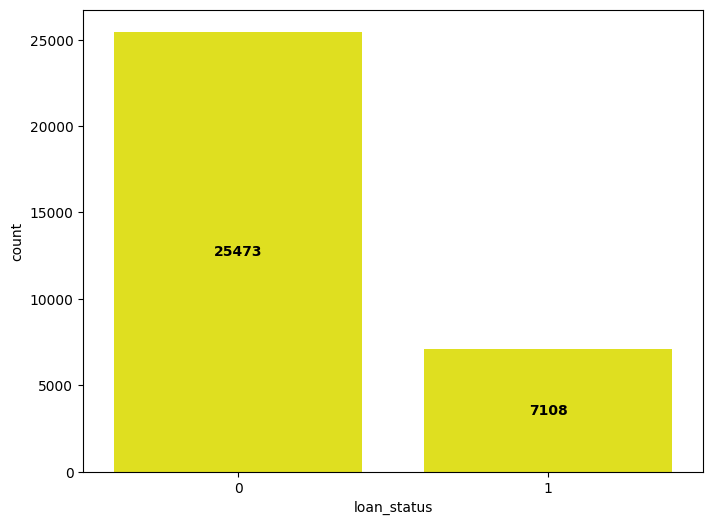

In [60]:
# plot the class imbalance
plt.figure(figsize=(8, 6))
ax = sns.countplot(data=df, x='loan_status', color = 'yellow')
for container in ax.containers:
    ax.bar_label(container, label_type='center', color='black', fontweight='bold')

plt.show()

-- There is a class imbalance and thus ML model will focus more on class "0" than class "1"<br>
    -- And to reduce the class imbalance we can use SMOTE or Class-weight

**Outlier check**
* Look for values that seem impossible, like age 144.
* These are signs of bad data entries.

In [61]:
# Statistical summary of the dataset
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


-- As we can see, max value of '***person_age***' is 144, which is an outlier.<br>
We will use box-plot to show outliers

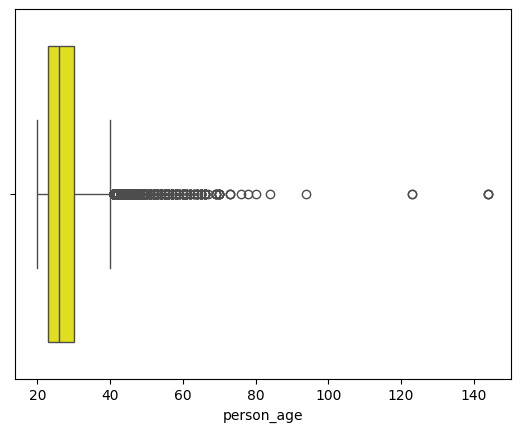

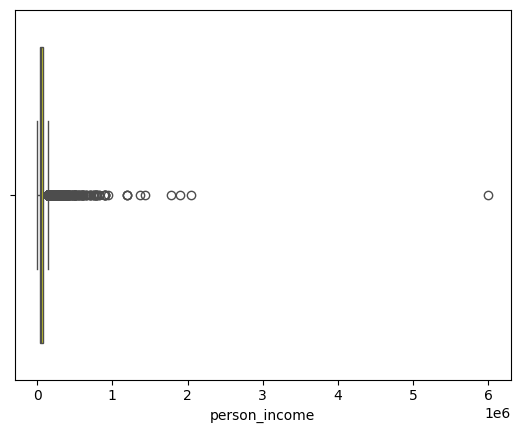

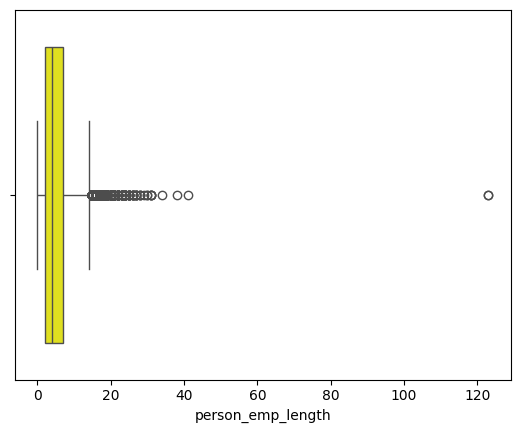

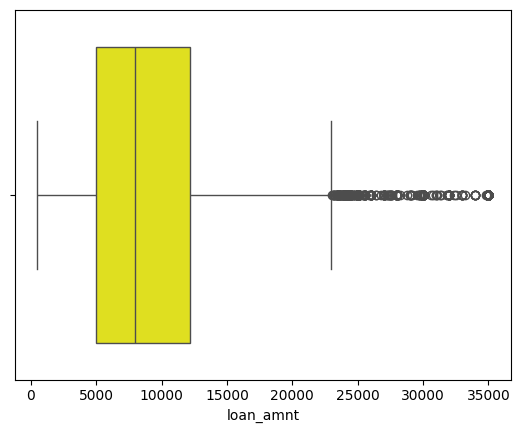

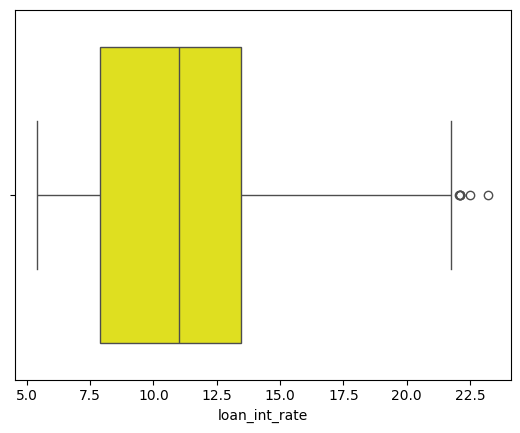

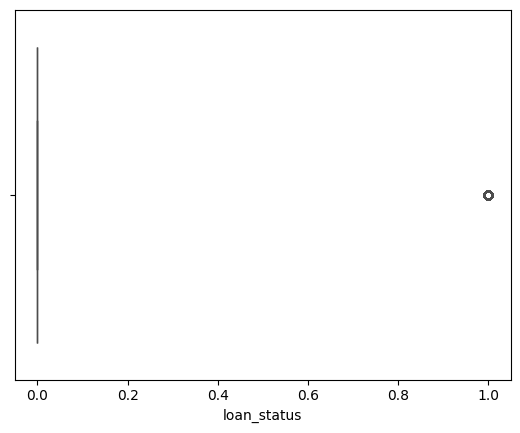

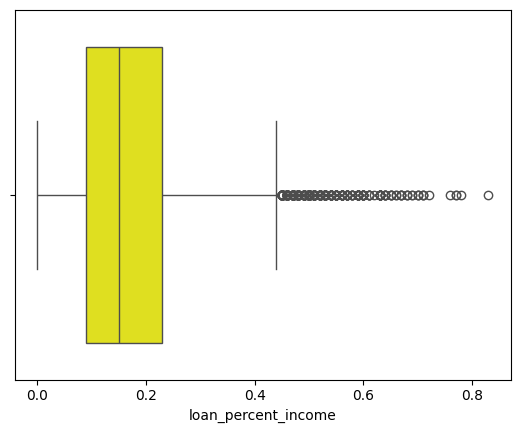

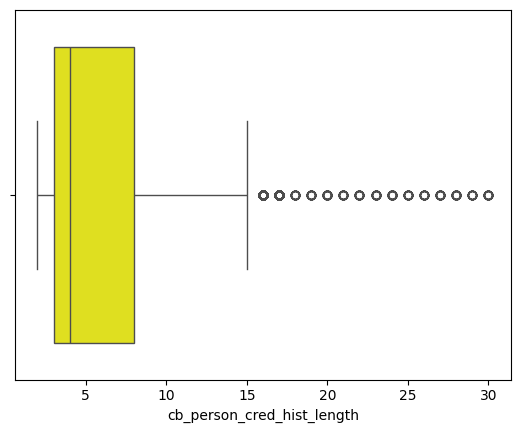

In [62]:
# As box plot can be used for numerical columns,
# we will extract numerical columns first
numerical_cols = df.select_dtypes(include=np.number).columns
numerical_cols

# creating box-plot
for i in numerical_cols:
  sns.boxplot(data=df, x=df[i], color='yellow')
  plt.show()



In [63]:
print("\nOutlier in person_age:")
print((df['person_age']>90).sum())

print("\nOutlier in person_income:")
print((df['person_income']>1000000).sum())

print("\nOutlier in person_emp_length:")
print((df['person_emp_length']>60).sum())


Outlier in person_age:
6

Outlier in person_income:
9

Outlier in person_emp_length:
2


**Correlation check**
* See how strongly features are related to each other.
* This helps us spot repeated or linked information.

<Axes: >

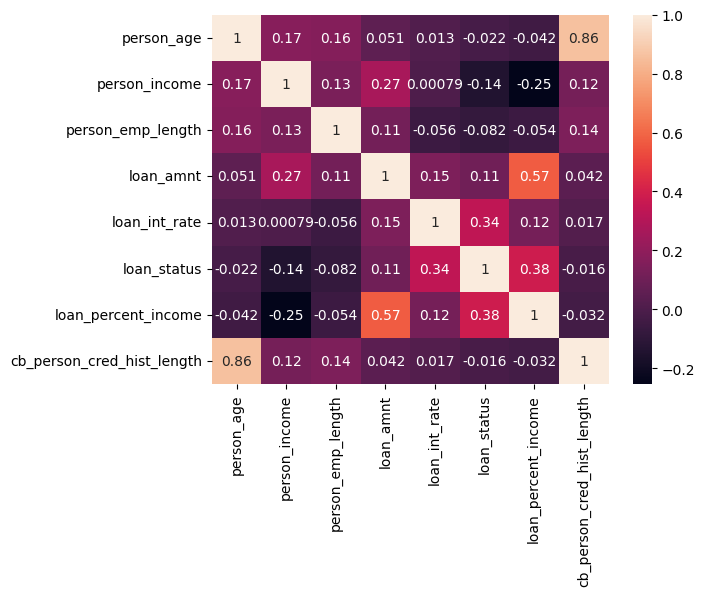

In [64]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

-- As we can see from the correlation matrix, most correlation found between ***person_age*** and ***cb_person_cred_hist_length***

# 3. Data Validation & Outlier Handling

1. Here we clean the data properly.
2. We remove duplicate rows.
3. We remove rows with an impossible age or work experience.
4. We remove rows with zero or negative income and loan amount.
5. We check if the interest rate looks realistic.
6. We also flag rows where numbers don't add up correctly.

In [65]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]}")

# remove duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates: {df_copy.shape[0]}")

Original Rows: 32581
Rows after removing duplicates: 32416


In [66]:
# Remove ages below 18 years and above 60 years
df_copy = df_copy[df_copy['person_age'] >= 18]
df_copy = df_copy[df_copy['person_age'] <= 100]

# Remove employment length greater than age or extreme outliers(>=60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

In [67]:
# Remove zero or negetive income and negetive loan_amount
df_copy = df_copy[df_copy['person_income'] > 0]
df_copy = df_copy[df_copy['loan_amnt'] > 0]

In [68]:
# print loan_int_rate maximum and minimum rate
print("Maximum loan_int_rate:", df_copy['loan_int_rate'].max())
print("Minimum loan_int_rate:", df_copy['loan_int_rate'].min())


Maximum loan_int_rate: 23.22
Minimum loan_int_rate: 5.42


# 4. Features, Target & Train-Test Split

* We separate the data into input features and the target.
* The target is whether the applicant defaulted or not.
* We split the data into a training part and a testing part.
* The model learns from the training part only.

In [69]:
x = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [70]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [71]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length',
                  'loan_amnt','loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


# 5. Handle Class Imbalance

* Very few people actually default in this data.
* If we ignore this, the model may just favor the majority class.
* We give more importance to the minority class during training.
* This helps the model actually learn to spot defaulters.

In [72]:
print('Train_value_counts:' , y_train.value_counts())
print('Bincounts:' , np.bincount(y_train))

Train_value_counts: loan_status
0    19772
1     5445
Name: count, dtype: int64
Bincounts: [19772  5445]


In [73]:
# getting scale_weights to put some weights on minority class
neg , pos = np.bincount(y_train)
scale_weights = neg/pos
scale_weights

np.float64(3.6312213039485766)

**Create Pipeline for Logistic-Regression**

# 6. Data Preprocessing — Pipelines & Column Transformer

* Raw data is not ready for a model directly.
* We need to prepare numeric and text columns differently.
* We will build a Pipeline for each model.
* We will use ColumnTransformer to apply different steps to different columns.

**Preprocessing for Logistic Regression**
* Fill missing numeric values.
* Scale numeric values, since this model is sensitive to scale.
* Convert category columns into numbers using one-hot encoding.

In [74]:
# Logistic Regression: impute + SCALE Numeric, impute + OneHotEncoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        # Pipeline fro numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),

        # Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown= 'ignore'))
        ]), categorical_cols)
    ]
)


**Preprocessing for XGBoost**
* Fill missing numeric values.
* No scaling needed here, since tree models don't need it.
* Convert category columns into numbers using one-hot encoding.

In [75]:
# XGBoost Pipeline : Numeri only (no scaling) , impute + OneHotEncoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        # Pipeline fro numerical columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),

        # Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown= 'ignore'))
        ]), categorical_cols)
    ]
)


# 7. Evaluation Helper Function
* We build one common function to check any model's performance.
* It will show accuracy, precision, recall, F1 score, and more.
* It will also show a confusion matrix and a precision-recall curve.

In [76]:
# We have to evaluate Logistic Model and XGBoost Model on the basis of their metrics

from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test):
  y_pred = model.predict(X_test)
  y_pred_prob = model.predict_proba(X_test)[:, 1]

  # Metrics
  accuracy = accuracy_score(y_test, y_pred)   # Overall Model's performance
  precision_s = precision_score(y_test, y_pred) # Of the ones I picked, how many were picked?
  recall_s = recall_score(y_test, y_pred)   # Out of everything that was really there, how much did you managed to find ?
  f1 = f1_score(y_test, y_pred)   # The harmonic mean of precision and recall ( the balance between them)


  # Confusion Matrix
  cm = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"Accuracy Score: {accuracy:.2f}")
  print(f"Precision Score: {precision_s:.2f}")
  print(f"Recall Score: {recall_s:.2f}")
  print(f"F1 Score: {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)

  # Plotting Confusion matrix
  sns.heatmap(cm, annot=True, fmt='g')
  plt.xlabel('Predicted Values')
  plt.ylabel('Actual Values')
  plt.title(f"{model_name} Confusion Matrix")
  plt.show()

  # Plotting ROC_AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

-- This is how we create a single fuction to show accuracy, precision, recall, F1 score in XGBoost and other models at once, and not required to recall them again and again

# 8. Stratified Cross-Validation

* One single train-test split may not be reliable.
* We split the training data into five folds instead.
* Each fold keeps the same default vs repaid ratio.
* We check the model's score across all folds.

In [77]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'ROC_AUC':'roc_auc',
    'Accuracy':'accuracy',
    'Precision':'precision',
    'Recall':'recall',
    'F1':'f1'
}

In [78]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [79]:
# XGBoost Model:
from xgboost import XGBClassifier
xg_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
     ('classifier', XGBClassifier(
         n_estimator=300, max_depth = 5, learning_rate = 0.1,
         scale_pos_weight = scale_weights, random_state=42,
     ))
])
xg_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_valu...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [80]:
# now we have to do some iterations to check how our model is performing
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xg_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC_AUC: {cv_results['test_ROC_AUC'].mean():.3f}")
                      print(f"Accuracy: {cv_results['test_Accuracy'].mean():.3f}")
                      print(f"Precision: {cv_results['test_Precision'].mean():.3f}")
                      print(f"Recall: {cv_results['test_Recall'].mean():.3f}")
                      print(f"F1: {cv_results['test_F1'].mean():.3f}")
                      print()

Logistic Regression
ROC_AUC: 0.871
Accuracy: 0.812
Precision: 0.545
Recall: 0.778
F1: 0.641

XGBoost
ROC_AUC: 0.939
Accuracy: 0.909
Precision: 0.791
Recall: 0.786
F1: 0.788



-- We have picked logistic regression model first and train our data<br>
-- Then after traing, we picked xgboost model to train our data<br>
-- Then we performed cross validation
* As we have 5 folds we are taking average in scoring
* Just because of class imbalance we are taking these scoring methods

In [81]:
# scoring matrix
cv_results

{'fit_time': array([0.64888811, 0.66190505, 0.64037108, 0.66430187, 0.37567949]),
 'score_time': array([0.11640239, 0.1171546 , 0.11547327, 0.11480975, 0.06462598]),
 'test_ROC_AUC': array([0.94306506, 0.93043619, 0.94080108, 0.94479977, 0.93782203]),
 'test_Accuracy': array([0.9129659 , 0.91237113, 0.90838786, 0.9109657 , 0.89867143]),
 'test_Precision': array([0.80545113, 0.82317682, 0.79000925, 0.78933092, 0.74870912]),
 'test_Recall': array([0.78696051, 0.75665748, 0.78420569, 0.80165289, 0.79889807]),
 'test_F1': array([0.79609847, 0.78851675, 0.78709677, 0.79544419, 0.77298978])}

# 9. Baseline Model — Logistic Regression

* We start with a simple model first.
* This becomes our benchmark to beat.
* We train it and check its score on the test data.

In [82]:
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Accuracy Score: 0.82
Precision Score: 0.56
Recall Score: 0.79
F1 Score: 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



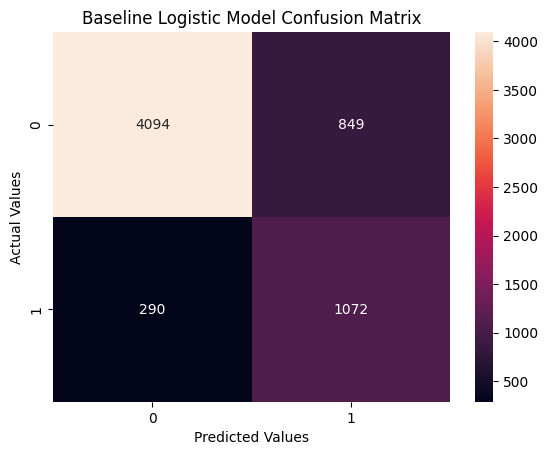

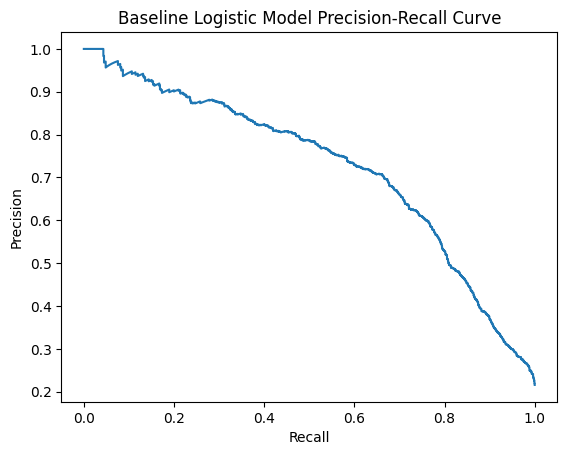

In [83]:
# Evaluate the Logistic Funcition
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

# 10. XGBoost Hyperparameter Tuning

* Now we move to a stronger model, XGBoost.
* A model has many settings called hyperparameters.
* We search for the best combination of these settings.
* We use cross-validation while searching, so the result is reliable.

In [84]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
                                 scale_pos_weight=scale_weights, random_state=42))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_valu...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Accuracy Score: 0.92
Precision Score: 0.82
Recall Score: 0.79
F1 Score: 0.81

XSBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



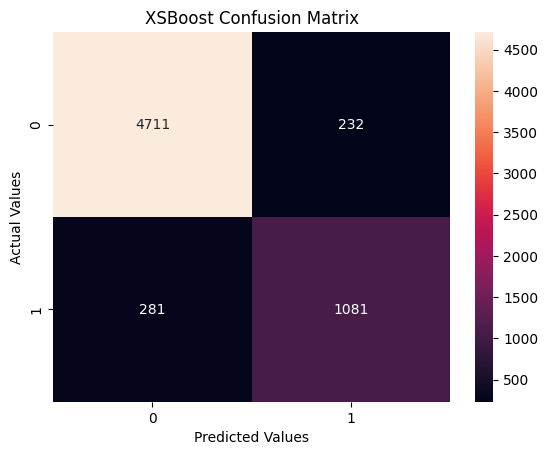

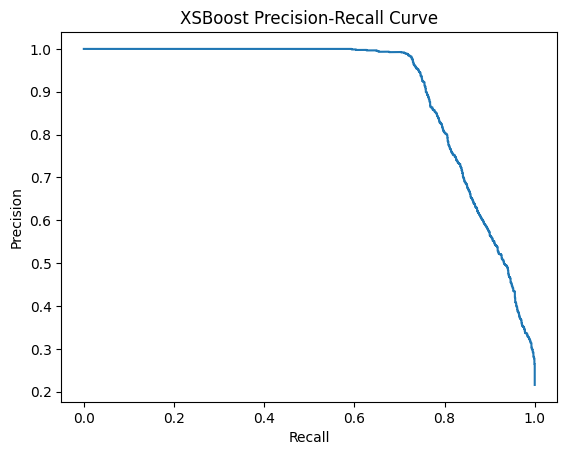

In [85]:
# Evaluate model
evaluate_model("XSBoost", xg_model, X_test, y_test)

In [86]:
# Performing hyper-parameter tuning
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}

In [87]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income'...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ff24a8929f0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ff247e81a70>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7ff24a8928d0>},
                   scoring='average_precision', verbose=1)

In [89]:
print(f"Best score after performing tuning: {random_search.best_score_:.2f}")

Best score after performing tuning: 0.90


In [88]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.6218550355789694),
 'classifier__gamma': np.float64(0.6103594395399048),
 'classifier__learning_rate': np.float64(0.1334938372925054),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 3,
 'classifier__n_estimators': 500,
 'classifier__subsample': np.float64(0.9415370841141216)}

# 11. Compare Both Models Side by Side

* We now compare Logistic Regression and XGBoost.
* We look at their scores together in one table.
* This helps us pick the better performing model.

Accuracy Score: 0.82
Precision Score: 0.56
Recall Score: 0.79
F1 Score: 0.65

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



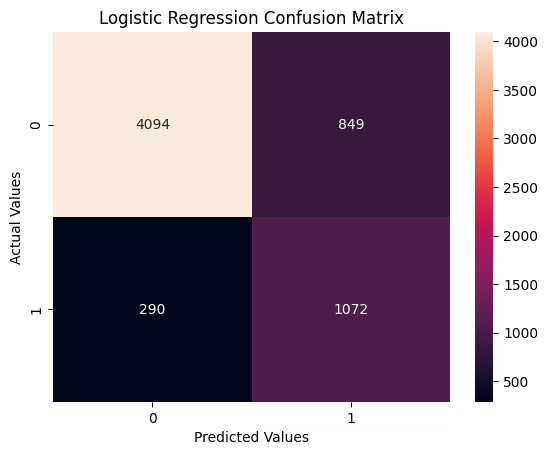

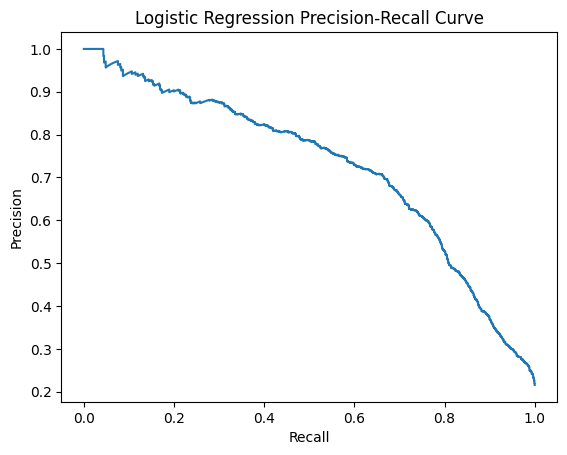

In [90]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)